# Example 4: feedback states

An ONNX model keeps nothing between two calls. Many useful models, though,
need to remember: a recurrent network has a hidden state, and an
autoregressive model looks at a window of past values.

ONNX2FMU solves this with **feedback states**. You export the model with its
memory as an explicit input *and* an explicit output, and you declare that
the two belong together. At each step the FMU stores the output and hands it
back as the input of the next step.

In this tutorial we build a model that keeps a history of its inputs and of
its own outputs, export it for both FMI 2.0 and FMI 3.0, and verify the
result against a plain Python loop.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import onnx
import pandas as pd
import torch
from torch import nn

## The model

The model receives three tensors:

- `u`, the new control values at the current step, with shape `(1, 5)`;
- `U`, the history of the previous nine control vectors, with shape `(9, 5)`;
- `X`, the history of the last ten outputs, with shape `(10, 3)`.

It returns:

- `x`, the output at the current step, with shape `(1, 3)`;
- `X1`, the output history with `x` appended and the oldest row dropped;
- `U1`, the control history with `u` appended and the oldest row dropped.

`U1` and `X1` are the updated versions of `U` and `X`. They need different
names because ONNX does not allow two nodes with the same name.

The output `x` is deliberately simple, so that we can recognise it in the
results: it picks three values from different rows of the control history,
that is, controls delayed by two, one and zero steps.

In [2]:
class ExampleModel(nn.Module):

    def forward(self, u, U, X):
        # Slide the control history: drop the oldest row, append the new one
        U1 = torch.concat((U[1:, :], u))
        # The output reads the history at three different delays
        x = torch.stack([U1[-3, 0], U1[-2, 1], U1[-1, 2]]).unsqueeze(0)
        # Slide the output history in the same way
        X1 = torch.concat((X[1:, :], x))
        return x, X1, U1


FEATURES = 5
TARGETS = 3
T = 10

u = torch.ones((1, FEATURES))
U = torch.ones((T - 1, FEATURES))
X = torch.ones((T, TARGETS))

model = ExampleModel()
model.eval()

print("input shapes: ", u.shape, U.shape, X.shape)
print("output shapes:", *[tensor.shape for tensor in model(u, U, X)])

input shapes:  torch.Size([1, 5]) torch.Size([9, 5]) torch.Size([10, 3])
output shapes: torch.Size([1, 3]) torch.Size([10, 3]) torch.Size([9, 5])


## Export to ONNX

In [3]:
model_name = "example4"
onnx_model_path = f"{model_name}.onnx"

torch.onnx.export(
    model,
    (u, U, X),
    onnx_model_path,
    input_names=["u", "U", "X"],
    output_names=["x", "X1", "U1"],
    external_data=False,  # keep the whole model in a single file
    verbose=False,
)

onnx_model = onnx.load(onnx_model_path)
onnx.checker.check_model(onnx_model)

## The model description

Only `u` is listed under `inputs` and only `x` under `outputs`: these are the
signals the user of the FMU connects.

The two histories go in the `feedbackStates` section. Each entry has a
`nameIn`, the input node that receives the value, and a `nameOut`, the output
node that produces it. The two nodes must have the same shape.

**Start values matter here.** They are the content of the memory at the first
step. ONNX2FMU uses `1.0` when no start value is given, so we set the control
input and its history to `0.0` to begin with an empty history. A list with
five values is broadcast over the nine rows of `U`. The output history `X`
keeps the default, because this toy model only stores it and never reads it
back.

We write the description twice, once per FMI version. Since the `name` is
also the FMU name, the two FMUs get different names.

In [4]:
model_description = {
    "name": "example4FMI2",
    "description": "Example to test FMU with feedback states.",
    "FMIVersion": "2.0",
    "inputs": [
        {
            "name": "u",
            "description": "A vector of control variables at time t.",
            "start": [0.0, 0.0, 0.0, 0.0, 0.0]
        }
    ],
    "outputs": [
        {
            "name": "x",
            "description": "The state of the system at time t+1."
        }
    ],
    "feedbackStates": [
        {
            "nameIn": "X",
            "nameOut": "X1",
            "description": "The history of states from t-N to t."
        },
        {
            "nameIn": "U",
            "nameOut": "U1",
            "description": "The history of control variables from t-N to t-1.",
            "start": [0.0, 0.0, 0.0, 0.0, 0.0]
        }
    ]
}

with open(f"{model_name}Description.json", "w", encoding="utf-8") as f:
    json.dump(model_description, f, indent=4)

model_description["name"] = "example4FMI3"
model_description["FMIVersion"] = "3.0"

with open(f"{model_name}DescriptionFMI3.json", "w", encoding="utf-8") as f:
    json.dump(model_description, f, indent=4)

## Reference data

The reference is a Python loop that does by hand what the FMU will do for us:
call the model, keep `U1` and `X1`, and pass them back in at the next step.

The control signal is a ramp: at step `k` all five controls are equal to `k`.
With the delays built into the model, we expect the three outputs to be the
ramp shifted by two, one and zero steps.

In [5]:
time_steps = 100
index = pd.Index(np.arange(time_steps), name="time")

U_hist = np.ones((time_steps, FEATURES)) * np.arange(time_steps)[:, None]
pd.DataFrame(
    U_hist,
    columns=[f"u_0_{i}" for i in range(FEATURES)],
    index=index,
).to_csv("Example4_in.csv")

reference = torch.empty((time_steps, TARGETS))
U = torch.zeros((T - 1, FEATURES))
X = torch.zeros((T, TARGETS))
with torch.no_grad():
    for i, u in enumerate(U_hist):
        x, X1, U1 = model(torch.tensor(u, dtype=torch.float32).unsqueeze(0), U, X)
        U, X = U1, X1      # the feedback, done by hand
        reference[i] = x

output = pd.DataFrame(
    reference.numpy(),
    columns=[f"x_0_{i}" for i in range(TARGETS)],
    index=index,
)
output.to_csv("Example4_ref.csv")
output.head()

,x_0_0,x_0_1,x_0_2
time,,,
0,0.0,0.0,0.0
1,0.0,0.0,1.0
2,0.0,1.0,2.0
3,1.0,2.0,3.0
4,2.0,3.0,4.0


## Build the FMUs

In [6]:
from loguru import logger
from onnx2fmu.app import build

logger.disable("onnx2fmu")  # keep the notebook output short

build(
    model_path=onnx_model_path,
    model_description_path=f"{model_name}Description.json",
    target_folder="temp",
)

build(
    model_path=onnx_model_path,
    model_description_path=f"{model_name}DescriptionFMI3.json",
    target_folder="temp",
)

A look at the variables of the FMU shows how feedback states are exposed.
They are named `<nameIn>_<nameOut>_<index>` and have `local` causality: you
can observe them, but you do not connect them.

In [7]:
from fmpy import read_model_description

fmu_description = read_model_description(f"{model_name}FMI2.fmu")

variables = pd.DataFrame(
    [{"name": v.name, "causality": v.causality, "start": v.start}
     for v in fmu_description.modelVariables]
)
print(variables.groupby("causality", sort=False).size())
variables[variables["causality"] == "local"].head()

causality
independent     1
input           5
output          3
local          75
dtype: int64


,name,causality,start
9,X_X1_0_0,local,1.0
10,X_X1_0_1,local,1.0
11,X_X1_0_2,local,1.0
12,X_X1_1_0,local,1.0
13,X_X1_1_1,local,1.0


## Simulate and compare

We simulate both FMUs. As in the previous examples, the first row of the
results is recorded at initialisation, and the row at time `t + 1` is the
output for the inputs at time `t`.

In [8]:
from fmpy import simulate_fmu

signals = np.genfromtxt("Example4_in.csv", delimiter=",", names=True)
output_names = list(output.columns)

fmu_results = {}
for fmi in ["FMI2", "FMI3"]:
    results = simulate_fmu(
        f"{model_name}{fmi}.fmu",
        start_time=0,
        stop_time=time_steps,
        input=signals,
        output=output_names,
        output_interval=1,
        validate=True,
    )
    df_out = pd.DataFrame(results).set_index("time")
    df_out = df_out.iloc[1:time_steps + 1].set_index(index)
    pd.testing.assert_frame_equal(df_out, output, check_dtype=False)
    fmu_results[fmi] = df_out
    print(f"{fmi}: the FMU matches the Python loop")

FMI2: the FMU matches the Python loop


FMI3: the FMU matches the Python loop


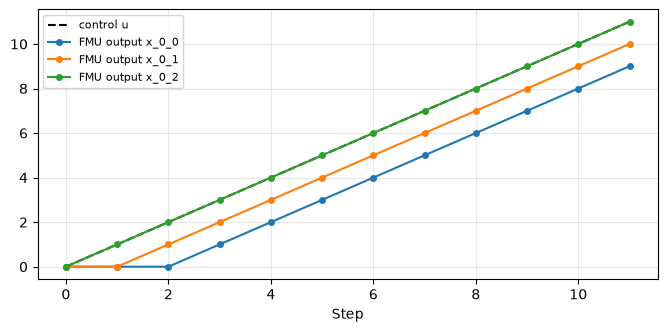

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
steps = slice(0, 12)
ax.plot(index[steps], U_hist[steps, 0], "k--", label="control u")
for column in output_names:
    ax.plot(index[steps], fmu_results["FMI3"][column][steps], "o-", ms=4, label=f"FMU output {column}")
ax.set_xlabel("Step")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

The outputs are the control ramp delayed by two, one and zero steps. The
delay can only come from the history stored between calls, so the feedback
loop is working: the FMU remembers.

## What next

- The section on feedback states in [Concepts](../../docs/concepts.md)
  summarises the rules.
- [Example 5](../example5/example5.ipynb) covers the other kind of state:
  continuous states integrated by a solver, in a Model Exchange FMU.